1. Business Understanding
2. Import Libraries
3. Load Datasets
4. Dataset Inspection
5. Data Quality Assessment
6. Data Cleaning
7. Merge Datasets
8. Feature Engineering
9. Exploratory Data Analysis (EDA)
10. Business Insights
11. Business Recommendations
12. Conclusion

# Olist Brazilian E-commerce Data Analysis

## Business Problem

Olist is a Brazilian e-commerce marketplace that connects sellers with customers. The company wants to analyze its sales, customer behavior, product performance, seller performance, payment methods, delivery efficiency, and customer reviews to identify business opportunities and improve overall performance.

## Project Objectives

- Analyze sales performance.
- Understand customer purchasing behavior.
- Identify top-performing product categories.
- Evaluate seller performance.
- Analyze payment preferences.
- Measure delivery performance.
- Study customer review patterns.
- Generate business recommendations based on insights.

Step 2: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
pd.set_option('display.max_columns', None)

In [2]:
import warnings
warnings.filterwarnings("ignore")
plt.style.use("ggplot")

In [3]:
customers = pd.read_csv(r"C:\Users\gk442\OneDrive\Desktop\Brazalian_Dataset\olist_customers_dataset.csv")
geolocation = pd.read_csv(r"C:\Users\gk442\OneDrive\Desktop\Brazalian_Dataset\olist_geolocation_dataset.csv")
order_items = pd.read_csv(r"C:\Users\gk442\OneDrive\Desktop\Brazalian_Dataset\olist_order_items_dataset.csv")
order_payments  = pd.read_csv(r"C:\Users\gk442\OneDrive\Desktop\Brazalian_Dataset\olist_order_payments_dataset.csv")
order_reviews  = pd.read_csv(r"C:\Users\gk442\OneDrive\Desktop\Brazalian_Dataset\olist_order_reviews_dataset.csv")
orders  = pd.read_csv(r"C:\Users\gk442\OneDrive\Desktop\Brazalian_Dataset\olist_orders_dataset.csv")
products  = pd.read_csv(r"C:\Users\gk442\OneDrive\Desktop\Brazalian_Dataset\olist_products_dataset.csv")
sellers  = pd.read_csv(r"C:\Users\gk442\OneDrive\Desktop\Brazalian_Dataset\olist_sellers_dataset.csv")
product_category_name_translation  = pd.read_csv(r"C:\Users\gk442\OneDrive\Desktop\Brazalian_Dataset\product_category_name_translation.csv")

Dataset Inspection

In [4]:
print("orders:", orders.shape)
print("customers:", customers.shape)
print("order_items:", order_items.shape)
print("products:", products.shape)
print("order_reviews:", order_reviews.shape)
print("order_payment:", order_payments.shape)
print("sellers:", sellers.shape)
print("geolocation:", geolocation.shape)
print("product_category_name_translation:", product_category_name_translation.shape)

orders: (99441, 8)
customers: (99441, 5)
order_items: (112650, 7)
products: (32951, 9)
order_reviews: (99224, 7)
order_payment: (103886, 5)
sellers: (3095, 4)
geolocation: (1000163, 5)
product_category_name_translation: (71, 2)


In [5]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
orders.tail()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00
99440,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-03-08 20:57:30,2018-03-09 11:20:28,2018-03-09 22:11:59,2018-03-16 13:08:30,2018-04-03 00:00:00


In [7]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [8]:
orders.describe()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-03-31 15:08:21,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [9]:
orders.duplicated().sum()

np.int64(0)

In [10]:
orders.nunique()

order_id                         99441
customer_id                      99441
order_status                         8
order_purchase_timestamp         98875
order_approved_at                90733
order_delivered_carrier_date     81018
order_delivered_customer_date    95664
order_estimated_delivery_date      459
dtype: int64

 Observations
- The Orders dataset contains **99,441 rows** and **8 columns**.
- `order_id` is the primary key, with all values unique.
- There are **no duplicate records** in the dataset.
- All timestamp columns (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, and `order_estimated_delivery_date`) are currently stored as **object** data type and should be converted to **datetime** to enable time-based analyses such as monthly sales trends, delivery time calculation, seasonal patterns, and order processing duration.
- Missing values are found only in delivery-related columns:
    - `order_approved_at` → 160 missing values
    - `order_delivered_carrier_date` → 1,783 missing values
    - `order_delivered_customer_date` → 2,965 missing values
- Missing delivery-related dates are present, particularly for orders that did not complete the normal delivery process. These records will be handled appropriately during data cleaning rather than simply removed.
- The dataset appears clean overall and is suitable for further analysis after converting the timestamp columns to datetime format.

In [11]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [12]:
customers.tail()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS
99440,274fa6071e5e17fe303b9748641082c8,84732c5050c01db9b23e19ba39899398,6703,cotia,SP


In [13]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [14]:
order_payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [15]:
order_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [16]:
geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [17]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [18]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [19]:
product_category_name_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


this will show the total missing values of each column in dataset:-

In [20]:
orders.isnull().sum()[orders.isnull().sum() > 0]

order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

In [21]:
customers.isnull().sum()[customers.isnull().sum() > 0]

Series([], dtype: int64)

In [22]:
order_items.isnull().sum()[order_items.isnull().sum() > 0]

Series([], dtype: int64)

In [23]:
products.isnull().sum()[products.isnull().sum() > 0]

product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [24]:
order_reviews.isnull().sum()[order_reviews.isnull().sum() > 0]

review_comment_title      87656
review_comment_message    58247
dtype: int64

In [25]:
order_payments.isnull().sum()[order_payments.isnull().sum() > 0]

Series([], dtype: int64)

In [26]:
sellers.isnull().sum()[sellers.isnull().sum() > 0]

Series([], dtype: int64)

In [27]:
geolocation.isnull().sum()[geolocation.isnull().sum() > 0]

Series([], dtype: int64)

In [28]:
product_category_name_translation.isnull().sum()[product_category_name_translation.isnull().sum() > 0]

Series([], dtype: int64)

### Investigating Missing Delivery Dates

In [29]:
orders.groupby("order_status")[
    [
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]
].apply(lambda x: x.isnull().sum())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


In [30]:
orders[
    orders["order_delivered_customer_date"].isnull()
]["order_status"].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

## Step 6: Data Cleaning

In [31]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

In [32]:
orders[date_columns].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [33]:
### Clean the product dataset
products["product_category_name"] = (
    products["product_category_name"]
    .fillna("unknown")
)

In [34]:
### Order Items
order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"],
    errors="coerce"
)

In [35]:
order_items["price"] = pd.to_numeric(
    order_items["price"],
    errors="coerce"
)

order_items["freight_value"] = pd.to_numeric(
    order_items["freight_value"],
    errors="coerce"
)

In [36]:
###Payment
order_payments["payment_value"] = pd.to_numeric(
    order_payments["payment_value"],
    errors="coerce"
)

In [37]:
order_payments["payment_installments"] = pd.to_numeric(
    order_payments["payment_installments"],
    errors="coerce"
)

In [38]:
### Reviews
review_date_columns = [
    "review_creation_date",
    "review_answer_timestamp"
]

for col in review_date_columns:
    order_reviews[col] = pd.to_datetime(
        order_reviews[col],
        errors="coerce"
    )

In [39]:
order_reviews["review_score"] = pd.to_numeric(
    order_reviews["review_score"],
    errors="coerce"
)

In [40]:
### Products
product_numeric_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for col in product_numeric_columns:
    products[col] = pd.to_numeric(
        products[col],
        errors="coerce"
    )

In [41]:
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Reviews:", order_reviews.shape)
print("Payments:", order_payments.shape)
print("Sellers:", sellers.shape)
print("Geolocation:", geolocation.shape)

Orders: (99441, 8)
Customers: (99441, 5)
Order Items: (112650, 7)
Products: (32951, 9)
Reviews: (99224, 7)
Payments: (103886, 5)
Sellers: (3095, 4)
Geolocation: (1000163, 5)


In [42]:
print("\nOrders date types:")
print(orders[date_columns].dtypes)

print("\nOrder Items date types:")
print(order_items["shipping_limit_date"].dtype)

print("\nReview date types:")
print(order_reviews[review_date_columns].dtypes)


Orders date types:
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Order Items date types:
datetime64[us]

Review date types:
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object


In [43]:
orders.groupby("order_status")[
    [
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]
].apply(lambda x: x.isnull().sum())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


In [44]:
orders[
    orders["order_delivered_customer_date"].isnull()
]["order_status"].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

### Handling Missing Delivery Dates

- Missing delivery dates are primarily associated with orders that did not complete the normal delivery process, such as shipped, canceled, unavailable, invoiced, and processing orders.
- These records will be retained because they are important for analyzing order and operational outcomes.
- Eight orders have an `order_status` of delivered but are missing the customer delivery date. These records will be treated as data-quality exceptions.
- Delivery-duration calculations will only use records with valid purchase and customer delivery timestamps.
- Missing dates will not be artificially imputed because doing so could distort delivery performance metrics.

In [45]:
# Identify delivered orders with missing customer delivery date
delivered_missing_date = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].isna())
]

print("Delivered orders missing customer delivery date:",
      len(delivered_missing_date))

delivered_missing_date[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
]

Delivered orders missing customer delivery date: 8


,order_id,order_status,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:05:11,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:05:55,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:14:02,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:09:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:09:12,2018-07-03 19:26:00,NaT,2018-07-19


In [46]:
orders["delivery_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

In [47]:
orders["delivery_days"].describe()

count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
max        209.628611
Name: delivery_days, dtype: float64

In [48]:
orders[orders["delivery_days"] < 0][
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "delivery_days"
    ]
]

,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_days


In [49]:
orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)   

In [50]:
orders["delivery_delay_days"].describe()

count    96476.000000
mean       -11.179120
std         10.186113
min       -146.016123
25%        -16.244384
50%        -11.948941
75%         -6.390000
max        188.975081
Name: delivery_delay_days, dtype: float64

### Delivery Performance Classification

In [51]:
orders["delivery_performance"] = np.select(
    [
        orders["delivery_delay_days"] > 0,
        orders["delivery_delay_days"] == 0,
        orders["delivery_delay_days"] < 0
    ],
    [
        "Late",
        "On Time",
        "Early"
    ],
    default="Not Delivered"
)

In [52]:
orders["delivery_performance"].value_counts()

delivery_performance
Early            88649
Late              7827
Not Delivered     2965
Name: count, dtype: int64

In [53]:
delivery_performance_pct = (
    orders["delivery_performance"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

delivery_performance_pct

delivery_performance
Early            89.15
Late              7.87
Not Delivered     2.98
Name: proportion, dtype: float64

89.15% of orders were delivered earlier than the estimated date, 
while 7.87% were delivered late. 2.98% did not have a completed customer delivery date.

### Late Delivery Performance by Customer State

In [54]:
# Merge customer state with order data
orders_state = orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# Calculate delivery performance by state
state_delivery = (
    orders_state.groupby("customer_state")["delivery_performance"]
    .value_counts()
    .unstack(fill_value=0)
)

# Calculate late delivery percentage
state_delivery["Late Delivery %"] = (
    state_delivery.get("Late", 0)
    / (
        state_delivery.get("Late", 0)
        + state_delivery.get("Early", 0)
    )
    * 100
)

state_delivery = (
    state_delivery
    .sort_values("Late Delivery %", ascending=False)
)

state_delivery.head(10)

delivery_performance,Early,Late,Not Delivered,Late Delivery %
customer_state,,,,
AL,302,95,16,23.929471
MA,576,141,30,19.665272
PI,400,76,19,15.966387
CE,1083,196,57,15.324472
SE,284,51,15,15.223881
BA,2799,457,124,14.035627
RJ,10689,1664,499,13.470412
TO,239,35,6,12.773723
PA,829,117,29,12.367865


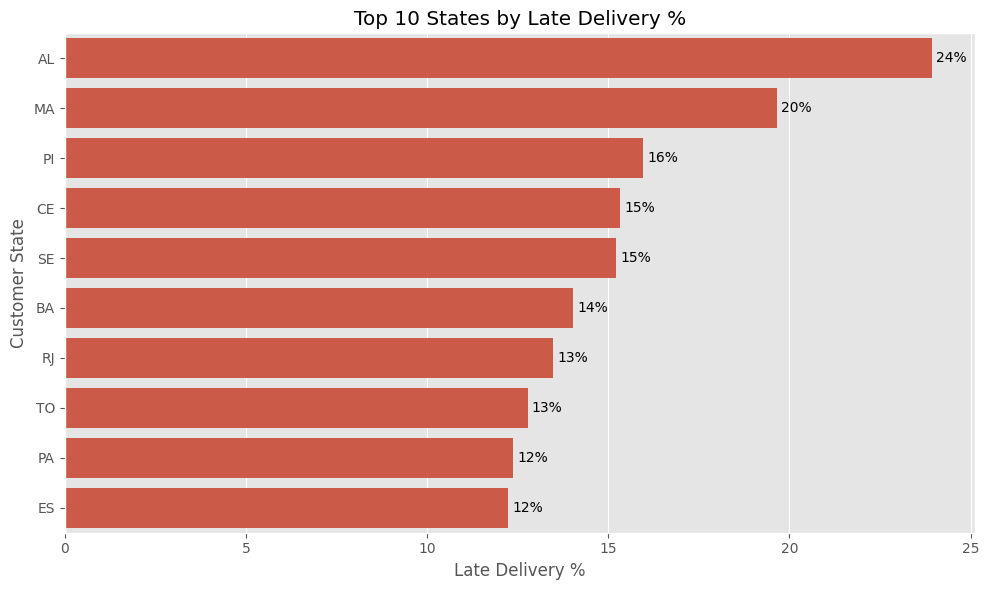

In [56]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=state_delivery.head(10)["Late Delivery %"],
    y=state_delivery.head(10).index
)

plt.title("Top 10 States by Late Delivery %")
plt.xlabel("Late Delivery %")
plt.ylabel("Customer State")

# Add data labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

What we've completed in Python so far
- Date/time cleaning ✅
- Missing delivery-date investigation ✅
- Delivery duration (delivery_days) ✅
- Delivery delay (delivery_delay_days) ✅
- Delivery performance classification ✅
- Early/Late/Not Delivered analysis ✅
- Late Delivery % by State ✅
- Visualization with whole-number data labels ✅

### Late Delivery Performance by Product Category

In [58]:
category_delivery = orders[
    orders["delivery_performance"].isin(["Early", "Late"])
][["order_id", "delivery_performance"]].merge(
    order_items[["order_id", "product_id"]],
    on="order_id",
    how="inner"
).merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
).merge(
    product_category_name_translation,
    on="product_category_name",
    how="left"
)

In [69]:
# . Calculate Late Delivery %
category_performance = (
    category_delivery
    .groupby("product_category_name_english")["delivery_performance"]
    .value_counts()
    .unstack(fill_value=0)
)

category_performance["Late Delivery %"] = (
    category_performance.get("Late", 0)
    / (
        category_performance.get("Late", 0)
        + category_performance.get("Early", 0)
    )
    * 100
)

category_performance = (
    category_performance
    .dropna(subset=["Late Delivery %"])
    .sort_values("Late Delivery %", ascending=False)
)

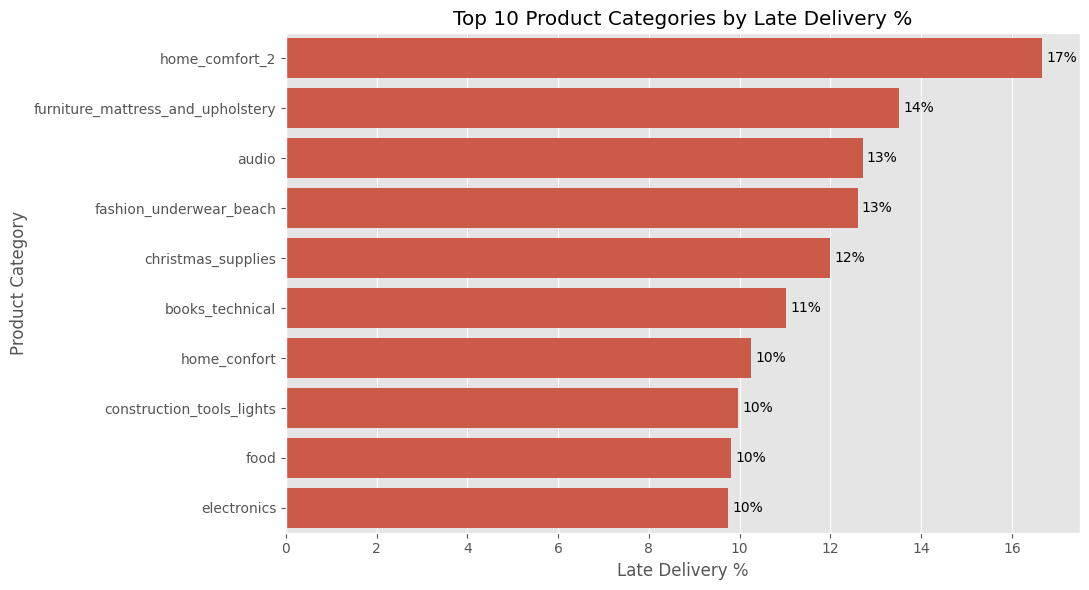

In [70]:
# Create the chart with whole-number labels
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=category_performance.head(10)["Late Delivery %"],
    y=category_performance.head(10).index
)

plt.title("Top 10 Product Categories by Late Delivery %")
plt.xlabel("Late Delivery %")
plt.ylabel("Product Category")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

### Late Delivery Performance by Seller

In [64]:
seller_delivery = orders[
    orders["delivery_performance"].isin(["Early", "Late"])
][["order_id", "delivery_performance"]].merge(
    order_items[["order_id", "seller_id"]],
    on="order_id",
    how="inner"
)

In [65]:
# Calculate the late-delivery percentage:
seller_performance = (
    seller_delivery
    .groupby("seller_id")["delivery_performance"]
    .value_counts()
    .unstack(fill_value=0)
)

seller_performance["Late Delivery %"] = (
    seller_performance.get("Late", 0)
    / (
        seller_performance.get("Late", 0)
        + seller_performance.get("Early", 0)
    )
    * 100
)

# Avoid highlighting sellers with very few orders
seller_performance["Total Orders"] = (
    seller_performance.get("Late", 0)
    + seller_performance.get("Early", 0)
)

seller_performance = seller_performance[
    seller_performance["Total Orders"] >= 50
].sort_values(
    "Late Delivery %",
    ascending=False
)

seller_performance.head(10)

delivery_performance,Early,Late,Late Delivery %,Total Orders
seller_id,,,,
54965bbe3e4f07ae045b90b0b8541f52,55,26,32.098765,81
2a1348e9addc1af5aaa619b1a3679d6b,36,15,29.411765,51
6039e27294dc75811c0d8a39069f52c0,55,19,25.675676,74
a49928bcdf77c55c6d6e05e09a9b4ca5,78,26,25.000000,104
602044f2c16190c2c6e45eb35c2e21cb,42,13,23.636364,55
06a2c3af7b3aee5d69171b0e14f0ee87,307,95,23.631841,402
beadbee30901a7f61d031b6b686095ad,52,16,23.529412,68
cac4c8e7b1ca6252d8f20b2fc1a2e4af,63,19,23.170732,82
ea566164622c6b439516ab18062c42cd,40,12,23.076923,52


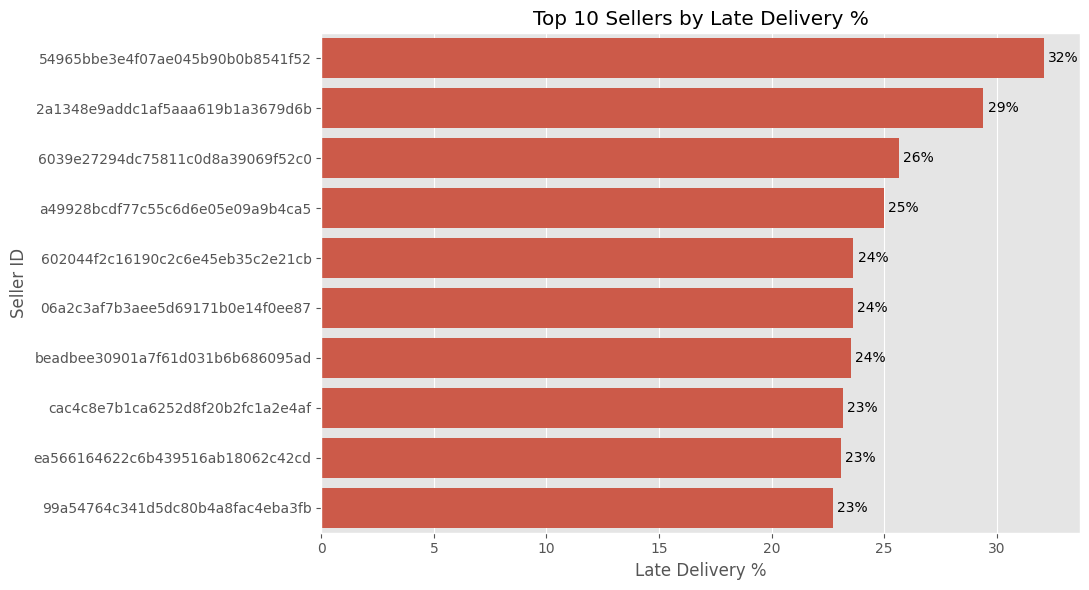

In [66]:
# Create the chart
plt.figure(figsize=(11, 6))

top_sellers = seller_performance.head(10)

ax = sns.barplot(
    x=top_sellers["Late Delivery %"],
    y=top_sellers.index
)

plt.title("Top 10 Sellers by Late Delivery %")
plt.xlabel("Late Delivery %")
plt.ylabel("Seller ID")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

### Delivery Performance vs Customer Satisfaction

In [67]:
delivery_review = orders[
    orders["delivery_performance"].isin(["Early", "Late"])
][["order_id", "delivery_performance"]].merge(
    order_reviews[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

In [68]:
# Now calculate the average review score:
delivery_review_summary = (
    delivery_review
    .groupby("delivery_performance")["review_score"]
    .agg(["count", "mean"])
    .reset_index()
)

delivery_review_summary["mean"] = delivery_review_summary["mean"].round(2)

delivery_review_summary

,delivery_performance,count,mean
0,Early,88658,4.29
1,Late,7701,2.57


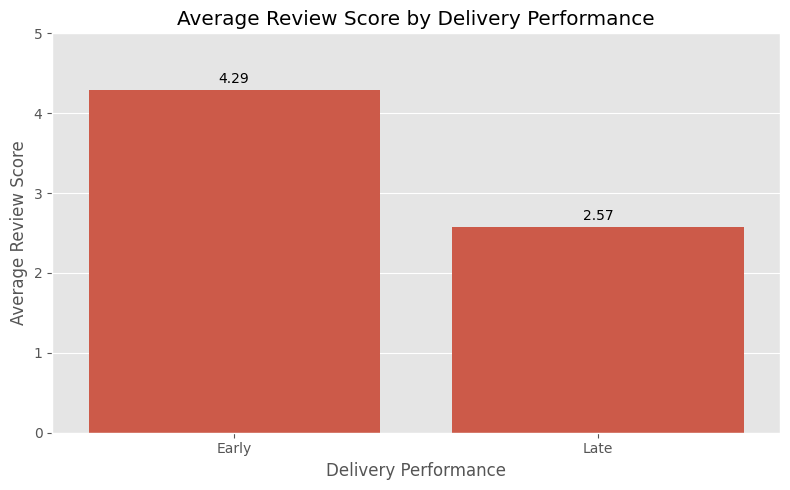

In [71]:
# Then create the chart:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=delivery_review_summary,
    x="delivery_performance",
    y="mean"
)

plt.title("Average Review Score by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

ate deliveries are strongly associated with lower customer satisfaction.
Customers whose orders were delivered early gave an average rating of 4.29/5, while customers experiencing late delivery gave only 2.57/5
Delivery delays have a significant negative impact on customer satisfaction, making on-time delivery a critical operational priority.